# Pivot TanHung_Cleaned_For_KAN và Tính P_224

Notebook này thực hiện:
1. Đọc file TanHung_Cleaned_For_KAN.csv
2. Pivot dữ liệu theo TIME và MaDiemDo
3. Tính P_224 = tổng P_clean của 5 trạm theo cùng TIME
4. Xuất file kết quả

## 1. Import Thư Viện và Đọc Dữ Liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
plt.style.use('seaborn-v0_8-darkgrid')

print("✅ Import thư viện thành công!")

✅ Import thư viện thành công!


In [2]:
# Đọc dữ liệu
INPUT_PATH = Path('TanHung_Cleaned_For_KAN_6years.csv')
OUTPUT_PATH = Path('TanHung_P224_6years_Pivoted.csv')

df = pd.read_csv(INPUT_PATH)
df['TIME'] = pd.to_datetime(df['TIME'])

print(f"Đã đọc dữ liệu: {len(df):,} records")
print(f"Khoảng thời gian: {df['TIME'].min()} → {df['TIME'].max()}")
print(f"Số trạm: {df['MaDiemDo'].nunique()}")
print(f"\nCác trạm:")
for station_id in sorted(df['MaDiemDo'].unique()):
    station_name = df[df['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
    count = len(df[df['MaDiemDo'] == station_id])
    print(f"  - {station_name} (Mã {station_id}): {count:,} records")

df.head()

Đã đọc dữ liệu: 413,376 records
Khoảng thời gian: 2020-02-09 00:00:00 → 2025-12-31 23:30:00
Số trạm: 4

Các trạm:
  - 474 Tân Hưng (Mã 4295): 103,344 records
  - 476 Tân Hưng (Mã 4447): 103,344 records
  - 478 Tân Hưng (Mã 4587): 103,344 records
  - 480 Tân Hưng (Mã 8667): 103,344 records


,TIME,MaDiemDo,TenDiemDo,UA,UB,UC,IA,IB,IC,CosF,P_kW_raw,P_clean,fill_method
0,2020-02-09 00:00:00,4295,474 Tân Hưng,13215.00,13257.98,13250.30,227.14,206.79,212.31,0.986666,8.51561,8.51561,original
1,2020-02-09 00:30:00,4295,474 Tân Hưng,13292.52,13312.47,13302.49,242.24,221.15,225.54,0.990000,9.19188,9.19188,original
2,2020-02-09 01:00:00,4295,474 Tân Hưng,13218.58,13242.63,13226.00,234.02,215.10,221.91,0.990000,8.95506,8.95506,original
3,2020-02-09 01:30:00,4295,474 Tân Hưng,12860.69,12899.84,12893.95,254.45,234.71,241.55,0.986666,9.47753,9.47753,original
4,2020-02-09 02:00:00,4295,474 Tân Hưng,12989.12,13017.51,12987.07,245.84,226.23,230.94,0.986666,9.03075,9.03075,original


In [3]:
# ## 2. Thống Kê Dữ Liệu Gốc

print("\n" + "=" * 80)
print("THỐNG KÊ DỮ LIỆU GỐC")
print("=" * 80)

# Thống kê P_clean
print(f"\nThống kê P_clean:")
print(f"  Min:    {df['P_clean'].min():.4f} kW")
print(f"  Max:    {df['P_clean'].max():.4f} kW")
print(f"  Mean:   {df['P_clean'].mean():.4f} kW")
print(f"  Median: {df['P_clean'].median():.4f} kW")
print(f"  Missing: {df['P_clean'].isna().sum():,} records ({df['P_clean'].isna().mean()*100:.2f}%)")

# Thống kê theo trạm
print(f"\nThống kê P_clean theo trạm:")
station_stats = df.groupby(['MaDiemDo', 'TenDiemDo'])['P_clean'].agg([
    ('count', 'count'),
    ('mean', 'mean'),
    ('median', 'median'),
    ('min', 'min'),
    ('max', 'max'),
    ('missing', lambda x: x.isna().sum())
]).reset_index()

display(station_stats)


THỐNG KÊ DỮ LIỆU GỐC

Thống kê P_clean:
  Min:    0.0000 kW
  Max:    20.0932 kW
  Mean:   5.8781 kW
  Median: 6.1230 kW
  Missing: 0 records (0.00%)

Thống kê P_clean theo trạm:


,MaDiemDo,TenDiemDo,count,mean,median,min,max,missing
0,4295,474 Tân Hưng,103344,6.566843,7.006820,0.0,19.243200,0
1,4447,476 Tân Hưng,103344,1.572201,0.630337,0.0,16.738270,0
2,4587,478 Tân Hưng,103344,7.364877,7.995585,0.0,20.093184,0
3,8667,480 Tân Hưng,103344,8.008644,8.779290,0.0,18.399600,0


In [4]:
# ## 3. Pivot Dữ Liệu - Tạo Cột Cho Mỗi Trạm

print("\n" + "=" * 80)
print("PIVOT DỮ LIỆU THEO TRẠM")
print("=" * 80)

# Pivot P_clean theo TIME và MaDiemDo
df_pivot = df.pivot(index='TIME', columns='MaDiemDo', values='P_clean')

# Đổi tên cột thành tên trạm
station_names = df[['MaDiemDo', 'TenDiemDo']].drop_duplicates().set_index('MaDiemDo')['TenDiemDo'].to_dict()
df_pivot.columns = [f"P_{station_names[col]}" for col in df_pivot.columns]

print(f"\nShape sau pivot: {df_pivot.shape}")
print(f"Số mốc thời gian: {len(df_pivot):,}")
print(f"Số cột (trạm): {len(df_pivot.columns)}")

print(f"\nCác cột:")
for col in df_pivot.columns:
    print(f"  - {col}")

df_pivot.head()


PIVOT DỮ LIỆU THEO TRẠM

Shape sau pivot: (103344, 4)
Số mốc thời gian: 103,344
Số cột (trạm): 4

Các cột:
  - P_474 Tân Hưng
  - P_476 Tân Hưng
  - P_478 Tân Hưng
  - P_480 Tân Hưng


,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng
TIME,,,,
2020-02-09 00:00:00,8.51561,2.28515,13.63768,5.20506
2020-02-09 00:30:00,9.19188,1.90428,13.43993,5.04392
2020-02-09 01:00:00,8.95506,1.69921,14.14549,5.11717
2020-02-09 01:30:00,9.47753,2.56102,13.88182,5.06834
2020-02-09 02:00:00,9.03075,2.82225,13.33739,5.25634


In [5]:
# ## 4. Tính P_224 - Tổng Công Suất 5 Trạm

print("\n" + "=" * 80)
print("TÍNH P_224 - TỔNG CÔNG SUẤT MBA 224")
print("=" * 80)

# Tính tổng P_clean của 5 trạm
df_pivot['P_224'] = df_pivot.sum(axis=1)

print(f"\nĐã tính P_224 = tổng P_clean của {len(df_pivot.columns)-1} trạm")

# Thống kê P_224
print(f"\nThống kê P_224:")
print(f"  Min:    {df_pivot['P_224'].min():.4f} kW")
print(f"  Max:    {df_pivot['P_224'].max():.4f} kW")
print(f"  Mean:   {df_pivot['P_224'].mean():.4f} kW")
print(f"  Median: {df_pivot['P_224'].median():.4f} kW")
print(f"  Missing: {df_pivot['P_224'].isna().sum():,} records ({df_pivot['P_224'].isna().mean()*100:.2f}%)")

df_pivot.head(10)


TÍNH P_224 - TỔNG CÔNG SUẤT MBA 224

Đã tính P_224 = tổng P_clean của 4 trạm

Thống kê P_224:
  Min:    0.0000 kW
  Max:    60.0034 kW
  Mean:   23.5126 kW
  Median: 24.7802 kW
  Missing: 0 records (0.00%)


,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng,P_224
TIME,,,,,
2020-02-09 00:00:00,8.51561,2.28515,13.63768,5.20506,29.64350
2020-02-09 00:30:00,9.19188,1.90428,13.43993,5.04392,29.58001
2020-02-09 01:00:00,8.95506,1.69921,14.14549,5.11717,29.91693
2020-02-09 01:30:00,9.47753,2.56102,13.88182,5.06834,30.98871
2020-02-09 02:00:00,9.03075,2.82225,13.33739,5.25634,30.44673
2020-02-09 02:30:00,8.94774,2.66599,13.49608,5.04637,30.15618
2020-02-09 03:00:00,8.88182,2.84422,12.90282,5.03417,29.66303
2020-02-09 03:30:00,8.29833,2.95409,13.18114,5.29295,29.72651
2020-02-09 04:00:00,9.25291,2.90038,13.29832,5.21239,30.66400


In [6]:
# ## 5. Kiểm Tra Missing Values

print("\n" + "=" * 80)
print("KIỂM TRA MISSING VALUES")
print("=" * 80)

# Đếm missing theo từng cột
missing_counts = df_pivot.isna().sum()
missing_pcts = df_pivot.isna().mean() * 100

missing_df = pd.DataFrame({
    'Column': missing_counts.index,
    'Missing_Count': missing_counts.values,
    'Missing_Pct': missing_pcts.values
}).sort_values('Missing_Count', ascending=False)

print(f"\nMissing values theo cột:")
display(missing_df)

# Kiểm tra các mốc thời gian có missing
rows_with_missing = df_pivot.isna().any(axis=1).sum()
print(f"\nSố mốc thời gian có ít nhất 1 trạm missing: {rows_with_missing:,} ({rows_with_missing/len(df_pivot)*100:.2f}%)")

# Kiểm tra các mốc có đủ 5 trạm
complete_rows = df_pivot.iloc[:, :-1].notna().all(axis=1).sum()  # Bỏ cột P_224
print(f"Số mốc thời gian có đủ 5 trạm: {complete_rows:,} ({complete_rows/len(df_pivot)*100:.2f}%)")


KIỂM TRA MISSING VALUES

Missing values theo cột:


,Column,Missing_Count,Missing_Pct
0,P_474 Tân Hưng,0,0.0
1,P_476 Tân Hưng,0,0.0
2,P_478 Tân Hưng,0,0.0
3,P_480 Tân Hưng,0,0.0
4,P_224,0,0.0



Số mốc thời gian có ít nhất 1 trạm missing: 0 (0.00%)
Số mốc thời gian có đủ 5 trạm: 103,344 (100.00%)



VẼ BIỂU ĐỒ P_224


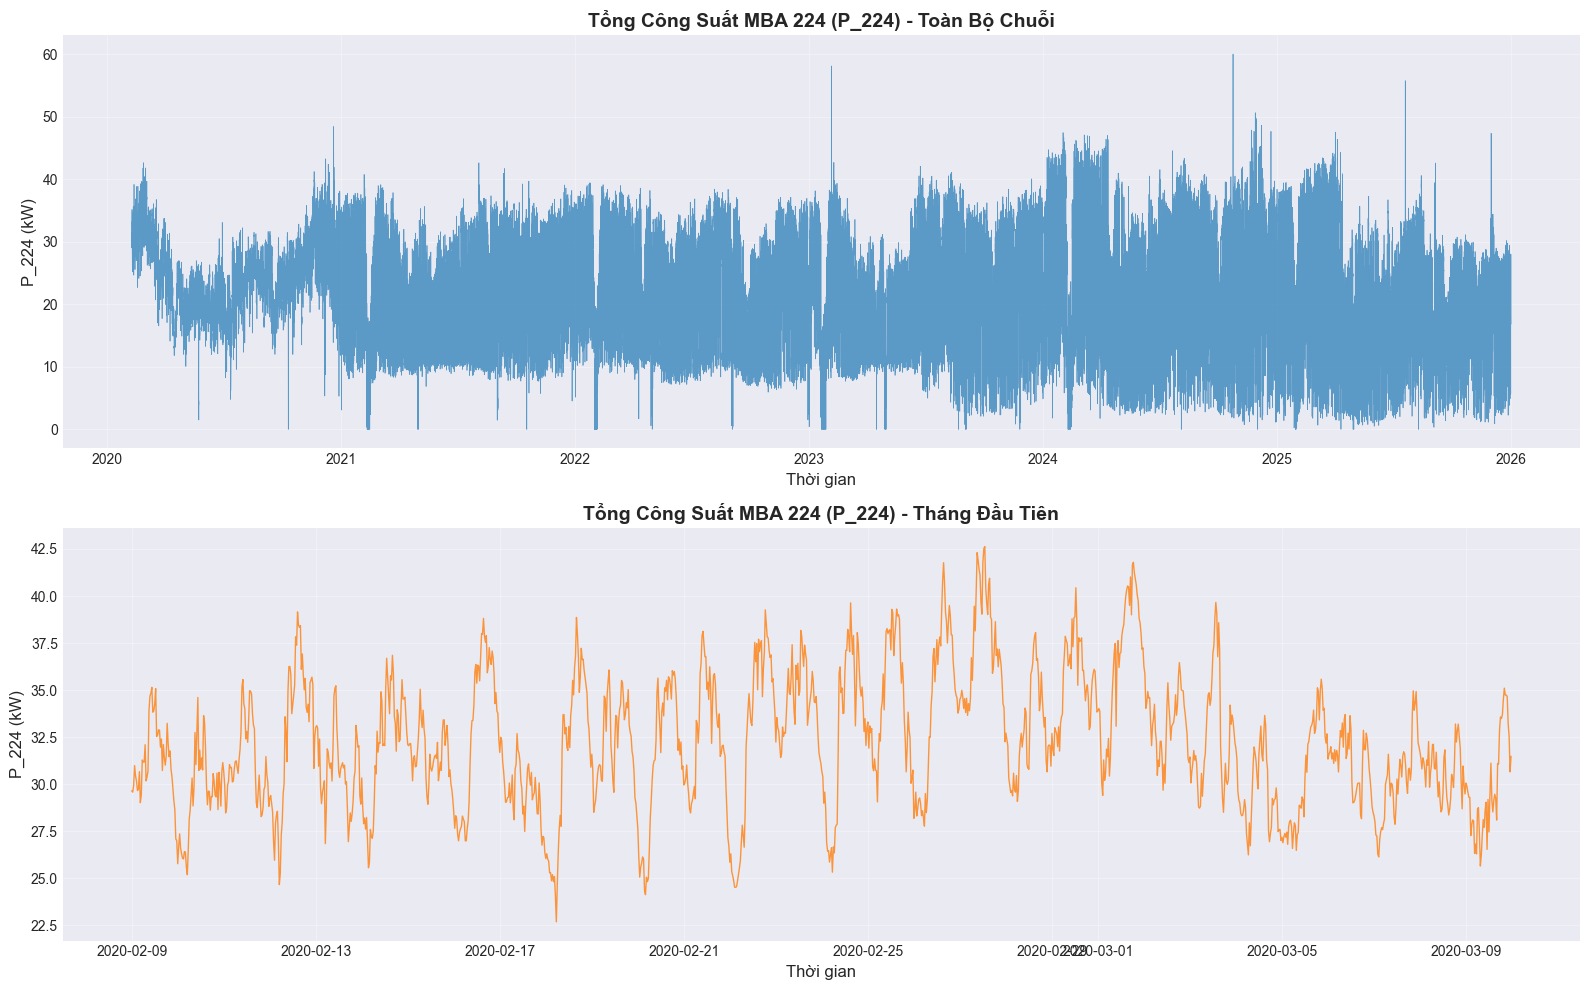

In [7]:
# ## 6. Vẽ Biểu Đồ P_224 Theo Thời Gian

print("\n" + "=" * 80)
print("VẼ BIỂU ĐỒ P_224")
print("=" * 80)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Toàn bộ chuỗi thời gian
ax1 = axes[0]
ax1.plot(df_pivot.index, df_pivot['P_224'], linewidth=0.5, alpha=0.7, color='tab:blue')
ax1.set_xlabel('Thời gian', fontsize=12)
ax1.set_ylabel('P_224 (kW)', fontsize=12)
ax1.set_title('Tổng Công Suất MBA 224 (P_224) - Toàn Bộ Chuỗi', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)

# Plot 2: Zoom vào 1 tháng đầu
sample_month = df_pivot.iloc[:1440]  # 30 ngày * 48 mẫu/ngày
ax2 = axes[1]
ax2.plot(sample_month.index, sample_month['P_224'], linewidth=1, alpha=0.8, color='tab:orange')
ax2.set_xlabel('Thời gian', fontsize=12)
ax2.set_ylabel('P_224 (kW)', fontsize=12)
ax2.set_title('Tổng Công Suất MBA 224 (P_224) - Tháng Đầu Tiên', fontsize=14, fontweight='bold')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


PHÂN TÍCH PHÂN BỐ P_224


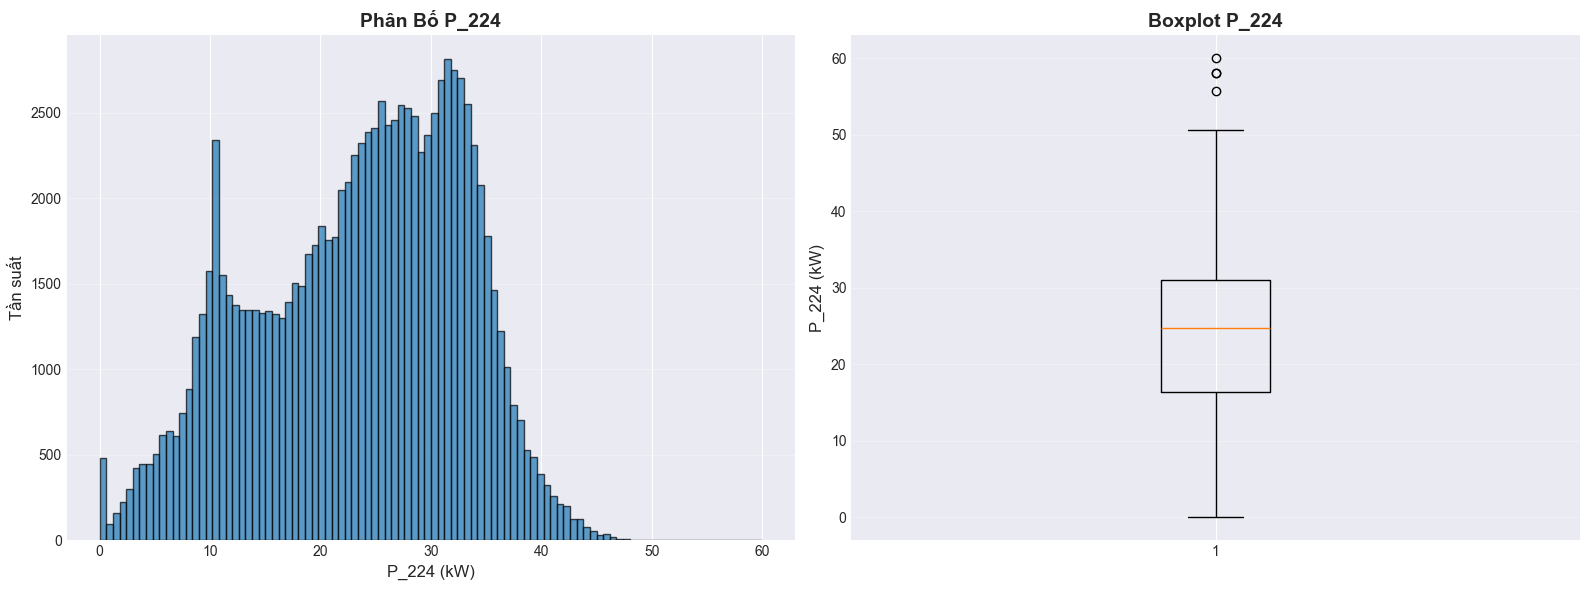


Phân vị P_224:
  P01: 2.53 kW
  P05: 7.38 kW
  P10: 10.10 kW
  P25: 16.39 kW
  P50: 24.78 kW
  P75: 31.04 kW
  P90: 34.68 kW
  P95: 36.75 kW
  P99: 41.16 kW


In [8]:
# ## 7. Phân Tích Phân Bố P_224

print("\n" + "=" * 80)
print("PHÂN TÍCH PHÂN BỐ P_224")
print("=" * 80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
ax1 = axes[0]
ax1.hist(df_pivot['P_224'].dropna(), bins=100, color='tab:blue', alpha=0.7, edgecolor='black')
ax1.set_xlabel('P_224 (kW)', fontsize=12)
ax1.set_ylabel('Tần suất', fontsize=12)
ax1.set_title('Phân Bố P_224', fontsize=14, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Boxplot
ax2 = axes[1]
ax2.boxplot(df_pivot['P_224'].dropna(), vert=True)
ax2.set_ylabel('P_224 (kW)', fontsize=12)
ax2.set_title('Boxplot P_224', fontsize=14, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Phân vị
print(f"\nPhân vị P_224:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    val = df_pivot['P_224'].quantile(p/100)
    print(f"  P{p:02d}: {val:.2f} kW")


PHÂN TÍCH THEO GIỜ VÀ NGÀY

Thống kê P_224 theo giờ:


,mean,median,min,max,std
hour,,,,,
0,28.956467,29.825405,5.339330,46.542910,5.969255
1,28.460990,29.234570,3.127420,48.391997,5.981816
2,28.113309,28.767070,4.890100,60.003444,6.100289
3,27.864246,28.594915,4.831510,46.625930,6.125905
4,27.653819,28.211640,0.000000,47.047210,6.150982
5,27.326374,27.810000,0.000000,58.102600,6.256726
6,26.378957,26.536825,0.000000,47.641610,6.531266
7,21.613119,21.534370,0.000000,43.899747,6.520611
8,16.595096,16.321985,0.000000,40.124460,6.438331


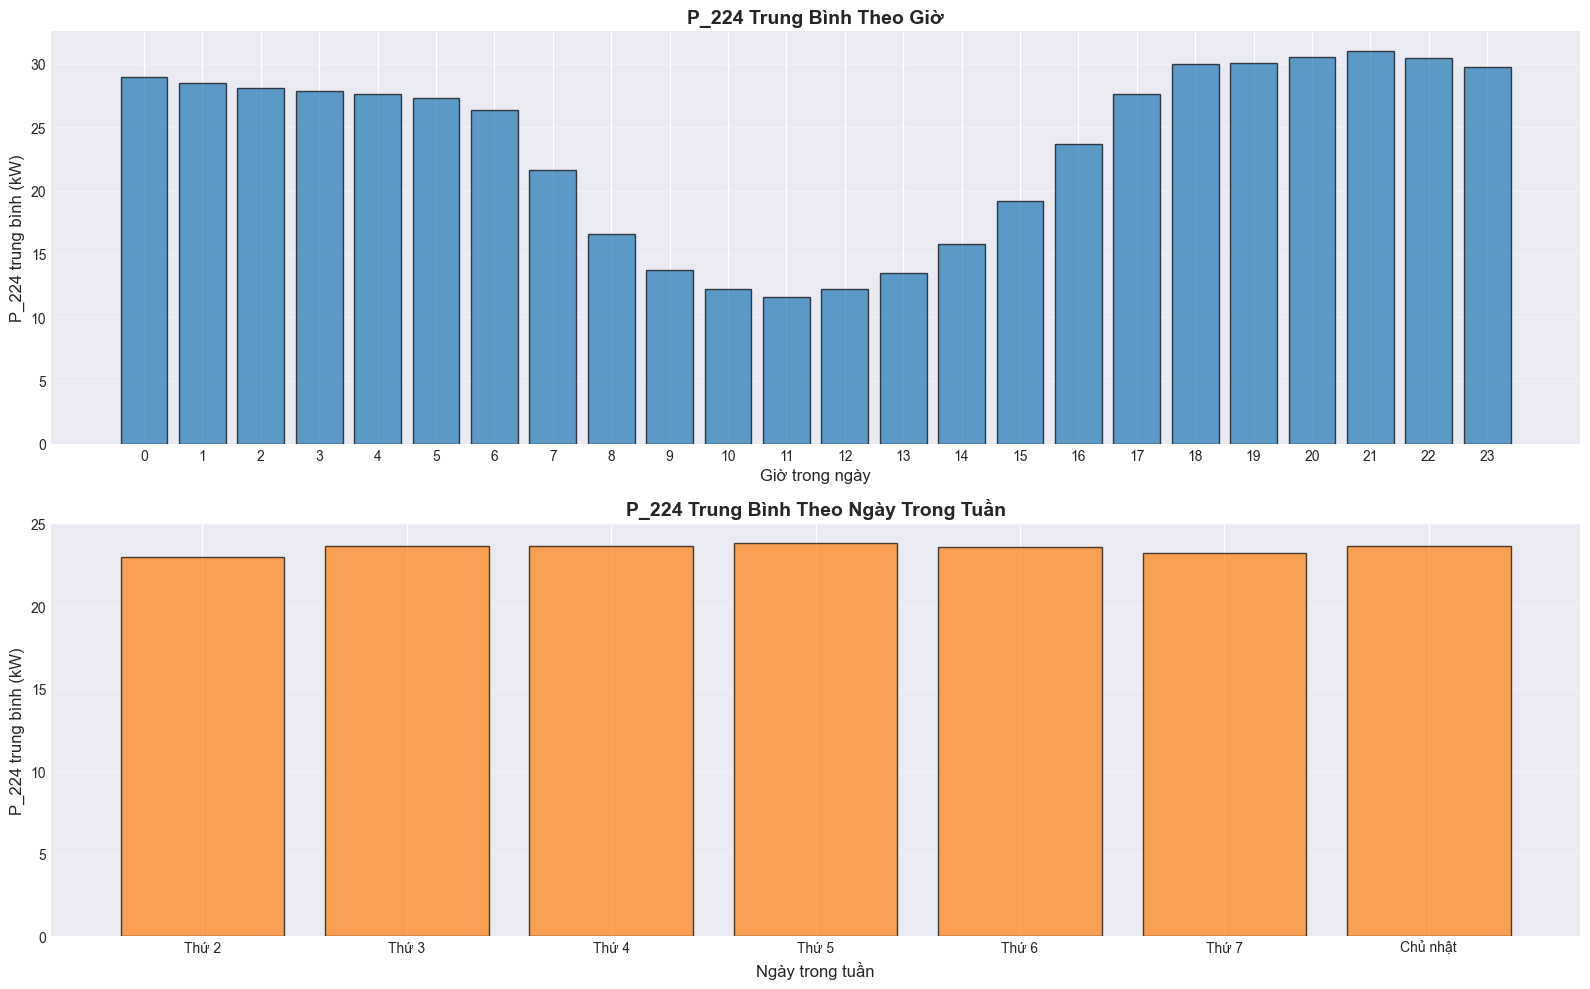

In [9]:
# ## 8. Phân Tích Theo Giờ và Ngày

print("\n" + "=" * 80)
print("PHÂN TÍCH THEO GIỜ VÀ NGÀY")
print("=" * 80)

# Tạo các cột thời gian
df_pivot['hour'] = df_pivot.index.hour
df_pivot['day_of_week'] = df_pivot.index.dayofweek
df_pivot['month'] = df_pivot.index.month

# Phân tích theo giờ
hourly_stats = df_pivot.groupby('hour')['P_224'].agg(['mean', 'median', 'min', 'max', 'std'])
print(f"\nThống kê P_224 theo giờ:")
display(hourly_stats)

# Vẽ biểu đồ theo giờ
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: P_224 trung bình theo giờ
ax1 = axes[0]
ax1.bar(hourly_stats.index, hourly_stats['mean'], color='tab:blue', alpha=0.7, edgecolor='black')
ax1.set_xlabel('Giờ trong ngày', fontsize=12)
ax1.set_ylabel('P_224 trung bình (kW)', fontsize=12)
ax1.set_title('P_224 Trung Bình Theo Giờ', fontsize=14, fontweight='bold')
ax1.set_xticks(range(24))
ax1.grid(axis='y', alpha=0.3)

# Plot 2: P_224 theo ngày trong tuần
weekly_stats = df_pivot.groupby('day_of_week')['P_224'].mean()
day_names = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ nhật']
ax2 = axes[1]
ax2.bar(range(7), weekly_stats.values, color='tab:orange', alpha=0.7, edgecolor='black')
ax2.set_xlabel('Ngày trong tuần', fontsize=12)
ax2.set_ylabel('P_224 trung bình (kW)', fontsize=12)
ax2.set_title('P_224 Trung Bình Theo Ngày Trong Tuần', fontsize=14, fontweight='bold')
ax2.set_xticks(range(7))
ax2.set_xticklabels(day_names)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# ## 9. Xuất File Kết Quả

print("\n" + "=" * 80)
print("XUẤT FILE KẾT QUẢ")
print("=" * 80)

# Reset index để TIME thành cột
df_export = df_pivot.reset_index()

# Xóa các cột phụ (hour, day_of_week, month)
cols_to_drop = ['hour', 'day_of_week', 'month']
df_export = df_export.drop(columns=[c for c in cols_to_drop if c in df_export.columns])

# Xuất file
df_export.to_csv(OUTPUT_PATH, index=False, encoding='utf-8-sig')

print(f"\n✅ Đã xuất file: {OUTPUT_PATH}")
print(f"   - Số dòng: {len(df_export):,}")
print(f"   - Số cột: {len(df_export.columns)}")
print(f"   - Kích thước: {OUTPUT_PATH.stat().st_size / 1024 / 1024:.2f} MB")

print(f"\nCác cột trong file:")
for i, col in enumerate(df_export.columns, 1):
    print(f"  {i}. {col}")

print(f"\n5 dòng đầu tiên:")
display(df_export.head())

print("\n✅ HOÀN THÀNH!")


XUẤT FILE KẾT QUẢ

✅ Đã xuất file: TanHung_P224_6years_Pivoted.csv
   - Số dòng: 103,344
   - Số cột: 6
   - Kích thước: 6.27 MB

Các cột trong file:
  1. TIME
  2. P_474 Tân Hưng
  3. P_476 Tân Hưng
  4. P_478 Tân Hưng
  5. P_480 Tân Hưng
  6. P_224

5 dòng đầu tiên:


,TIME,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng,P_224
0,2020-02-09 00:00:00,8.51561,2.28515,13.63768,5.20506,29.64350
1,2020-02-09 00:30:00,9.19188,1.90428,13.43993,5.04392,29.58001
2,2020-02-09 01:00:00,8.95506,1.69921,14.14549,5.11717,29.91693
3,2020-02-09 01:30:00,9.47753,2.56102,13.88182,5.06834,30.98871
4,2020-02-09 02:00:00,9.03075,2.82225,13.33739,5.25634,30.44673



✅ HOÀN THÀNH!


In [11]:
# ## 10. Gộp Dữ Liệu Thời Tiết

print("\n" + "=" * 80)
print("GỘP DỮ LIỆU THỜI TIẾT")
print("=" * 80)

# Đọc dữ liệu thời tiết
WEATHER_PATH = Path('weather_today_data.csv')
df_weather = pd.read_csv(WEATHER_PATH)
df_weather['TIME'] = pd.to_datetime(df_weather['TIME'])

print(f"\nĐã đọc dữ liệu thời tiết: {len(df_weather):,} records")
print(f"Khoảng thời gian: {df_weather['TIME'].min()} → {df_weather['TIME'].max()}")
print(f"\nCác cột thời tiết:")
for col in df_weather.columns:
    print(f"  - {col}")

# Làm tròn TIME của df_export về giờ chẵn để merge
df_export['TIME_hour'] = df_export['TIME'].dt.floor('h')

# Chỉ giữ các cột cần thiết từ weather (bỏ các cột trùng)
weather_cols = ['TIME', 'temp', 'rhum', 'prcp', 'wspd']
df_weather_merge = df_weather[weather_cols].copy()
df_weather_merge = df_weather_merge.rename(columns={'TIME': 'TIME_hour'})

# Merge dữ liệu thời tiết vào df_export
df_export = df_export.merge(df_weather_merge, on='TIME_hour', how='left')

# Xóa cột TIME_hour tạm
df_export = df_export.drop(columns=['TIME_hour'])

print(f"\n✅ Đã gộp dữ liệu thời tiết!")
print(f"   - Số dòng sau merge: {len(df_export):,}")
print(f"   - Số cột sau merge: {len(df_export.columns)}")

# Kiểm tra missing values của các cột thời tiết
print(f"\nKiểm tra missing values các cột thời tiết:")
for col in ['temp', 'rhum', 'prcp', 'wspd']:
    missing = df_export[col].isna().sum()
    missing_pct = df_export[col].isna().mean() * 100
    print(f"  - {col}: {missing:,} missing ({missing_pct:.2f}%)")

# Hiển thị 10 dòng đầu
print(f"\n10 dòng đầu tiên sau khi gộp:")
display(df_export.head(10))



GỘP DỮ LIỆU THỜI TIẾT

Đã đọc dữ liệu thời tiết: 55,104 records
Khoảng thời gian: 2020-01-01 00:00:00 → 2026-04-14 23:00:00

Các cột thời tiết:
  - TIME
  - temp
  - rhum
  - prcp
  - wspd
  - Date
  - Year
  - Month
  - Hour
  - DayOfWeek

✅ Đã gộp dữ liệu thời tiết!
   - Số dòng sau merge: 103,344
   - Số cột sau merge: 10

Kiểm tra missing values các cột thời tiết:
  - temp: 0 missing (0.00%)
  - rhum: 0 missing (0.00%)
  - prcp: 0 missing (0.00%)
  - wspd: 0 missing (0.00%)

10 dòng đầu tiên sau khi gộp:


,TIME,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng,P_224,temp,rhum,prcp,wspd
0,2020-02-09 00:00:00,8.51561,2.28515,13.63768,5.20506,29.64350,26.5,55,0.0,10.4
1,2020-02-09 00:30:00,9.19188,1.90428,13.43993,5.04392,29.58001,26.5,55,0.0,10.4
2,2020-02-09 01:00:00,8.95506,1.69921,14.14549,5.11717,29.91693,25.8,56,0.0,8.5
3,2020-02-09 01:30:00,9.47753,2.56102,13.88182,5.06834,30.98871,25.8,56,0.0,8.5
4,2020-02-09 02:00:00,9.03075,2.82225,13.33739,5.25634,30.44673,25.2,57,0.0,8.2
5,2020-02-09 02:30:00,8.94774,2.66599,13.49608,5.04637,30.15618,25.2,57,0.0,8.2
6,2020-02-09 03:00:00,8.88182,2.84422,12.90282,5.03417,29.66303,24.6,57,0.0,7.8
7,2020-02-09 03:30:00,8.29833,2.95409,13.18114,5.29295,29.72651,24.6,57,0.0,7.8
8,2020-02-09 04:00:00,9.25291,2.90038,13.29832,5.21239,30.66400,24.0,59,0.0,7.3
9,2020-02-09 04:30:00,8.96972,1.77245,13.27392,5.00243,29.01852,24.0,59,0.0,7.3



THỐNG KÊ DỮ LIỆU THỜI TIẾT

Thống kê các biến thời tiết:


,temp,rhum,prcp,wspd
count,103344.000000,103344.000000,103344.000000,103344.000000
mean,27.321234,78.080992,0.304314,7.769637
std,3.090964,16.510831,1.153431,4.052107
min,17.800000,25.000000,0.000000,0.000000
25%,25.000000,67.000000,0.000000,4.800000
50%,26.700000,81.000000,0.000000,7.100000
75%,29.500000,93.000000,0.100000,10.100000
max,38.700000,100.000000,24.700000,30.900000


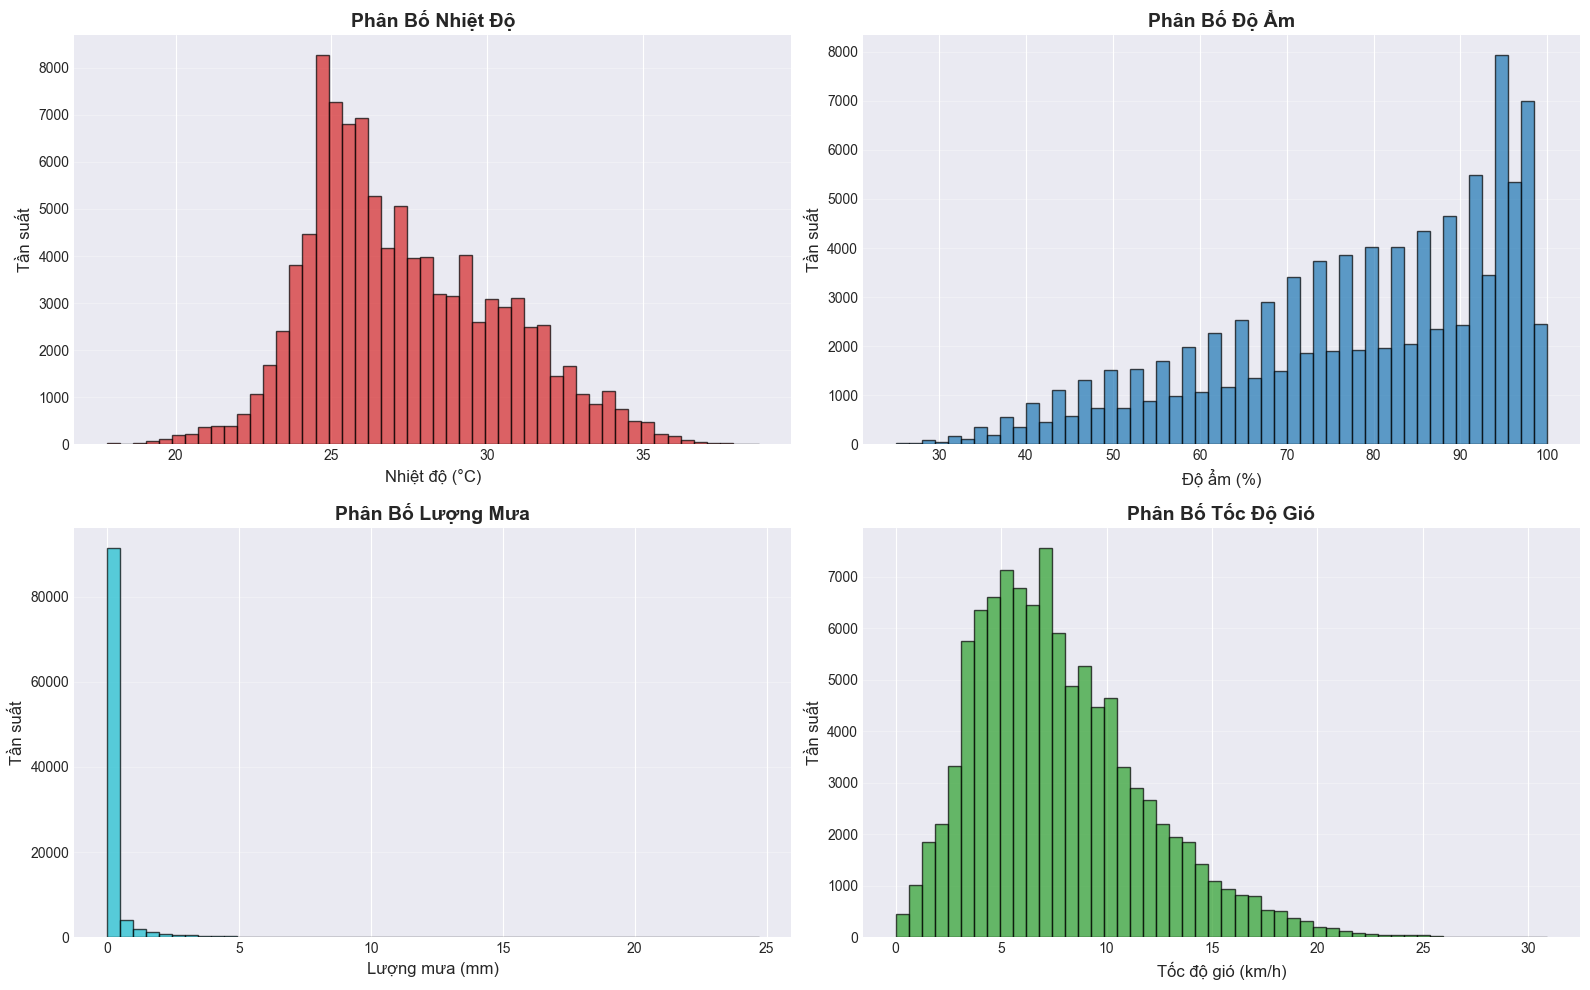

In [12]:
# %%
# ## 11. Thống Kê Dữ Liệu Thời Tiết

print("\n" + "=" * 80)
print("THỐNG KÊ DỮ LIỆU THỜI TIẾT")
print("=" * 80)

# Thống kê các biến thời tiết
weather_vars = ['temp', 'rhum', 'prcp', 'wspd']
weather_stats = df_export[weather_vars].describe()

print(f"\nThống kê các biến thời tiết:")
display(weather_stats)

# Vẽ biểu đồ phân bố
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Temperature
ax1 = axes[0, 0]
ax1.hist(df_export['temp'].dropna(), bins=50, color='tab:red', alpha=0.7, edgecolor='black')
ax1.set_xlabel('Nhiệt độ (°C)', fontsize=12)
ax1.set_ylabel('Tần suất', fontsize=12)
ax1.set_title('Phân Bố Nhiệt Độ', fontsize=14, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Humidity
ax2 = axes[0, 1]
ax2.hist(df_export['rhum'].dropna(), bins=50, color='tab:blue', alpha=0.7, edgecolor='black')
ax2.set_xlabel('Độ ẩm (%)', fontsize=12)
ax2.set_ylabel('Tần suất', fontsize=12)
ax2.set_title('Phân Bố Độ Ẩm', fontsize=14, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Precipitation
ax3 = axes[1, 0]
ax3.hist(df_export['prcp'].dropna(), bins=50, color='tab:cyan', alpha=0.7, edgecolor='black')
ax3.set_xlabel('Lượng mưa (mm)', fontsize=12)
ax3.set_ylabel('Tần suất', fontsize=12)
ax3.set_title('Phân Bố Lượng Mưa', fontsize=14, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

# Wind Speed
ax4 = axes[1, 1]
ax4.hist(df_export['wspd'].dropna(), bins=50, color='tab:green', alpha=0.7, edgecolor='black')
ax4.set_xlabel('Tốc độ gió (km/h)', fontsize=12)
ax4.set_ylabel('Tần suất', fontsize=12)
ax4.set_title('Phân Bố Tốc Độ Gió', fontsize=14, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()




PHÂN TÍCH TƯƠNG QUAN P_224 VỚI THỜI TIẾT

Ma trận tương quan:


,P_224,temp,rhum,prcp,wspd
P_224,1.000000,-0.409236,0.229872,-0.022228,-0.031040
temp,-0.409236,1.000000,-0.730768,-0.064089,0.089945
rhum,0.229872,-0.730768,1.000000,0.154226,-0.275728
prcp,-0.022228,-0.064089,0.154226,1.000000,0.075373
wspd,-0.031040,0.089945,-0.275728,0.075373,1.000000


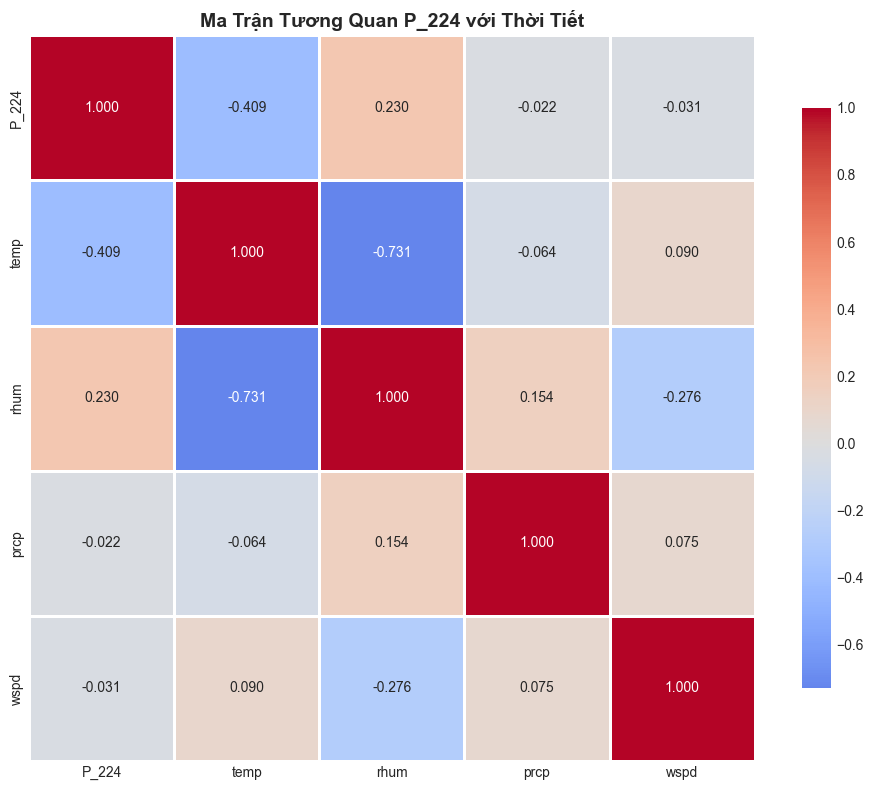


Tương quan với P_224:
  - rhum: 0.2299
  - prcp: -0.0222
  - wspd: -0.0310
  - temp: -0.4092


In [13]:
# %%
# ## 12. Phân Tích Tương Quan P_224 với Thời Tiết

print("\n" + "=" * 80)
print("PHÂN TÍCH TƯƠNG QUAN P_224 VỚI THỜI TIẾT")
print("=" * 80)

# Tính correlation
corr_cols = ['P_224', 'temp', 'rhum', 'prcp', 'wspd']
corr_matrix = df_export[corr_cols].corr()

print(f"\nMa trận tương quan:")
display(corr_matrix)

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Ma Trận Tương Quan P_224 với Thời Tiết', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# In correlation với P_224
print(f"\nTương quan với P_224:")
p224_corr = corr_matrix['P_224'].drop('P_224').sort_values(ascending=False)
for var, corr in p224_corr.items():
    print(f"  - {var}: {corr:.4f}")



In [14]:
# %%
# ## 13. Xuất File Cuối Cùng (Có Thời Tiết)

print("\n" + "=" * 80)
print("XUẤT FILE CUỐI CÙNG")
print("=" * 80)

# Xuất file với thời tiết
OUTPUT_FINAL = Path('TanHung_P224_6Years_With_Weather.csv')
df_export.to_csv(OUTPUT_FINAL, index=False, encoding='utf-8-sig')

print(f"\n✅ Đã xuất file cuối cùng: {OUTPUT_FINAL}")
print(f"   - Số dòng: {len(df_export):,}")
print(f"   - Số cột: {len(df_export.columns)}")
print(f"   - Kích thước: {OUTPUT_FINAL.stat().st_size / 1024 / 1024:.2f} MB")

print(f"\nCác cột trong file cuối cùng:")
for i, col in enumerate(df_export.columns, 1):
    print(f"  {i:2d}. {col}")

print(f"\n5 dòng đầu tiên:")
display(df_export.head())

print(f"\n5 dòng cuối cùng:")
display(df_export.tail())

print("\n✅ HOÀN THÀNH TẤT CẢ!")
print(f"\nĐã tạo 2 file:")
print(f"  1. {OUTPUT_PATH} - Chỉ có P_224 (không có thời tiết)")
print(f"  2. {OUTPUT_FINAL} - Có P_224 + thời tiết (temp, rhum, prcp, wspd)")


XUẤT FILE CUỐI CÙNG

✅ Đã xuất file cuối cùng: TanHung_P224_6Years_With_Weather.csv
   - Số dòng: 103,344
   - Số cột: 10
   - Kích thước: 7.87 MB

Các cột trong file cuối cùng:
   1. TIME
   2. P_474 Tân Hưng
   3. P_476 Tân Hưng
   4. P_478 Tân Hưng
   5. P_480 Tân Hưng
   6. P_224
   7. temp
   8. rhum
   9. prcp
  10. wspd

5 dòng đầu tiên:


,TIME,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng,P_224,temp,rhum,prcp,wspd
0,2020-02-09 00:00:00,8.51561,2.28515,13.63768,5.20506,29.64350,26.5,55,0.0,10.4
1,2020-02-09 00:30:00,9.19188,1.90428,13.43993,5.04392,29.58001,26.5,55,0.0,10.4
2,2020-02-09 01:00:00,8.95506,1.69921,14.14549,5.11717,29.91693,25.8,56,0.0,8.5
3,2020-02-09 01:30:00,9.47753,2.56102,13.88182,5.06834,30.98871,25.8,56,0.0,8.5
4,2020-02-09 02:00:00,9.03075,2.82225,13.33739,5.25634,30.44673,25.2,57,0.0,8.2



5 dòng cuối cùng:


,TIME,P_474 Tân Hưng,P_476 Tân Hưng,P_478 Tân Hưng,P_480 Tân Hưng,P_224,temp,rhum,prcp,wspd
103339,2025-12-31 21:30:00,10.96924,3.35205,3.07129,0.539550,17.932130,25.0,68,0.0,6.4
103340,2025-12-31 22:00:00,10.94483,3.49609,3.17383,0.557140,18.171890,24.5,71,0.0,3.3
103341,2025-12-31 22:30:00,10.37598,3.63037,2.99804,0.518045,17.522435,24.5,71,0.0,3.3
103342,2025-12-31 23:00:00,10.17578,3.54004,2.75390,0.514490,16.984210,23.8,69,0.0,8.1
103343,2025-12-31 23:30:00,10.01709,3.47656,2.82959,0.506850,16.830090,23.8,69,0.0,8.1



✅ HOÀN THÀNH TẤT CẢ!

Đã tạo 2 file:
  1. TanHung_P224_6years_Pivoted.csv - Chỉ có P_224 (không có thời tiết)
  2. TanHung_P224_6Years_With_Weather.csv - Có P_224 + thời tiết (temp, rhum, prcp, wspd)


Nhiệt độ theo giờ trong ngày:


,Trung bình,Min,Max
TIME,,,
0,25.379331,20.5,30.5
1,25.030144,19.9,30.0
2,24.721691,19.5,29.5
3,24.436832,19.0,29.2
4,24.205759,18.5,28.9
5,24.015095,18.0,28.8
6,23.959173,17.8,28.8
7,25.041477,18.2,30.1
8,26.641709,20.1,31.4



🔥 Giờ nóng nhất: 13h với nhiệt độ trung bình 31.3°C


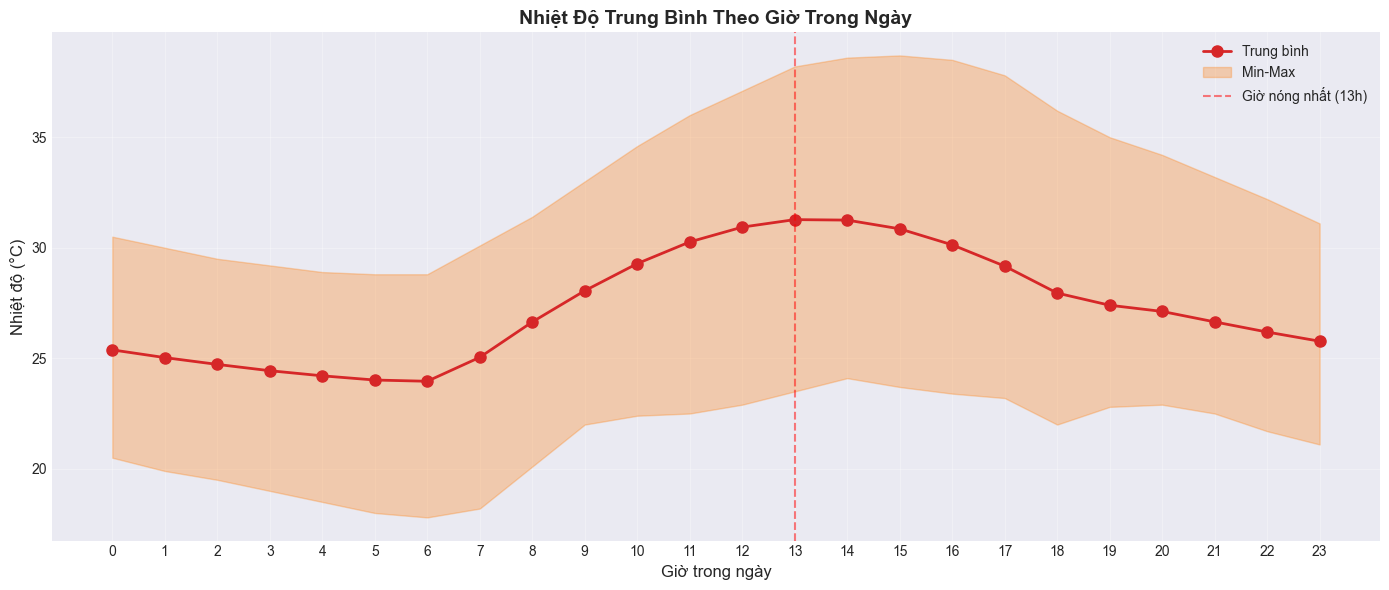

In [15]:
# Xem nhiệt độ trung bình theo giờ trong ngày
temp_by_hour = df_export.groupby(df_export['TIME'].dt.hour)['temp'].agg(['mean', 'min', 'max'])
temp_by_hour.columns = ['Trung bình', 'Min', 'Max']

print("Nhiệt độ theo giờ trong ngày:")
display(temp_by_hour)

# Tìm giờ nóng nhất
hottest_hour = temp_by_hour['Trung bình'].idxmax()
hottest_temp = temp_by_hour['Trung bình'].max()
print(f"\n🔥 Giờ nóng nhất: {hottest_hour:02d}h với nhiệt độ trung bình {hottest_temp:.1f}°C")

# Vẽ biểu đồ
plt.figure(figsize=(14, 6))
plt.plot(temp_by_hour.index, temp_by_hour['Trung bình'], marker='o', linewidth=2, markersize=8, color='tab:red', label='Trung bình')
plt.fill_between(temp_by_hour.index, temp_by_hour['Min'], temp_by_hour['Max'], alpha=0.3, color='tab:orange', label='Min-Max')
plt.axvline(x=hottest_hour, color='red', linestyle='--', alpha=0.5, label=f'Giờ nóng nhất ({hottest_hour}h)')
plt.xlabel('Giờ trong ngày', fontsize=12)
plt.ylabel('Nhiệt độ (°C)', fontsize=12)
plt.title('Nhiệt Độ Trung Bình Theo Giờ Trong Ngày', fontsize=14, fontweight='bold')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
